# Data Structure analysis

In this notebook, we analyze the overall data structure: how big is our dataset, how much missing data is there and what other observations can we do.

Our objective is answering this questions:


1. How many pigs, pens, and days are there?

2. Which pigs  have been in the farm from start to finish and which ones have been removed or transferred?
3. Is data consistent (in other words, do we have dupplicated data)?
4. Do we have impossible values?
5. How are outliers distributed across the dataset?
6. Do we have missing data? Can we caracterize this missigness?
7. Which variables can have leakage?


The analysis will be usefull to make the following decissions:

1. Do we need to filter data by quality?

2. What we do with missing data?

## Preeliminaries: Loading the dataset

In [1]:
import pandas as pd
import numpy as np

In [2]:
PATH = "C:/Users/ericp/Desktop/PigLF/PigLF-health-forecast/data/raw/Batch4_PigLF_animal_dia.csv"   # Change depending on your file location

df = pd.read_csv(PATH, parse_dates=["Date"])

df.head()

,Date,Fattening_day,Week,Animal_ID,Pen,Feed_intake_kg,Number_visits,Duration_min,Feeding_rate_g_min,Body_weight_kg,ADG_kg_d,FCR,RFI_kg_d,Water_use_L,Respiratory_score,Incidencias,Incidencias_tipo,Water_use_pen_L,Animals_in_pen,Reliable_day
0,2026-05-18,1,1,182617,1,0.717,12.0,47.35,16.77,26.25,0.583,1.630,-0.477,2.55,33,0,NaN,28.0,11,False
1,2026-05-19,2,1,182617,1,0.903,21.0,53.50,21.91,26.36,0.548,1.758,-0.463,3.27,38,0,NaN,36.0,11,True
2,2026-05-20,3,1,182617,1,1.098,12.0,59.40,41.82,27.00,0.375,2.527,-0.445,4.18,54,0,NaN,46.0,11,True
3,2026-05-21,4,1,182617,1,1.086,15.0,61.43,17.71,27.82,0.508,1.975,-0.422,4.18,38,0,NaN,46.0,11,True
4,2026-05-22,5,1,182617,1,1.009,15.0,62.05,14.98,28.14,0.595,1.819,-0.367,4.27,53,0,NaN,47.0,11,True


## 1. Dataset shape: How many pigs, pens and days are there?

In [3]:
df.shape

# Left value -> Number of observations
# Right value -> Number of variables

(14361, 20)

In [4]:
df.info()

# List of all variables in the dataset and their types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14361 entries, 0 to 14360
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Date                14361 non-null  datetime64[ns]
 1   Fattening_day       14361 non-null  int64         
 2   Week                14361 non-null  int64         
 3   Animal_ID           14361 non-null  int64         
 4   Pen                 14361 non-null  int64         
 5   Feed_intake_kg      14338 non-null  float64       
 6   Number_visits       14338 non-null  float64       
 7   Duration_min        14338 non-null  float64       
 8   Feeding_rate_g_min  14338 non-null  float64       
 9   Body_weight_kg      14230 non-null  float64       
 10  ADG_kg_d            14309 non-null  float64       
 11  FCR                 13987 non-null  float64       
 12  RFI_kg_d            14309 non-null  float64       
 13  Water_use_L         13197 non-null  float64   

In [5]:
n_pigs = df["Animal_ID"].nunique()

print("Number of different pigs:", n_pigs)

Number of different pigs: 119


In [6]:
n_pens = df["Pen"].nunique()

print("Number of different pens:", n_pens)

Number of different pens: 10


In [7]:
total_days = (df["Date"].max() - df["Date"].min()).days + 1

print("Total days:", total_days)

Total days: 123


In [8]:
days_with_data = df["Date"].dt.date.nunique()

print("Days with data:", days_with_data)

Days with data: 123


## 2. Which pigs have been in the farm from start to finish and which ones have been removed or transfered?

In [9]:
import sys
sys.path.append("../src")

from utils import (load_data, pig_summary, status_counts, withdrawals_by_pen,
                   plot_pig_timeline, plot_withdrawals_by_pen, outlier_summary, iqr_fences, is_outlier, weekly_outlier_stats, weekly_breakdown,
                   animal_outlier_stats, outlier_flags, group_outlier_stats)

In [10]:
pig = pig_summary(df)

In [11]:
withdrawals_by_pen(pig)

status,Complete,Withdrawn,total,pct_withdrawn
pen,,,,
1,8,3,11,27.3
2,11,1,12,8.3
3,11,1,12,8.3
4,11,1,12,8.3
5,12,0,12,0.0
6,11,1,12,8.3
7,12,0,12,0.0
8,11,1,12,8.3
9,12,0,12,0.0


(<Figure size 1200x1628 with 1 Axes>,
 <Axes: title={'center': 'Stay of each pig in the dataset (by pen)'}, ylabel='Pigs (n=119)'>)

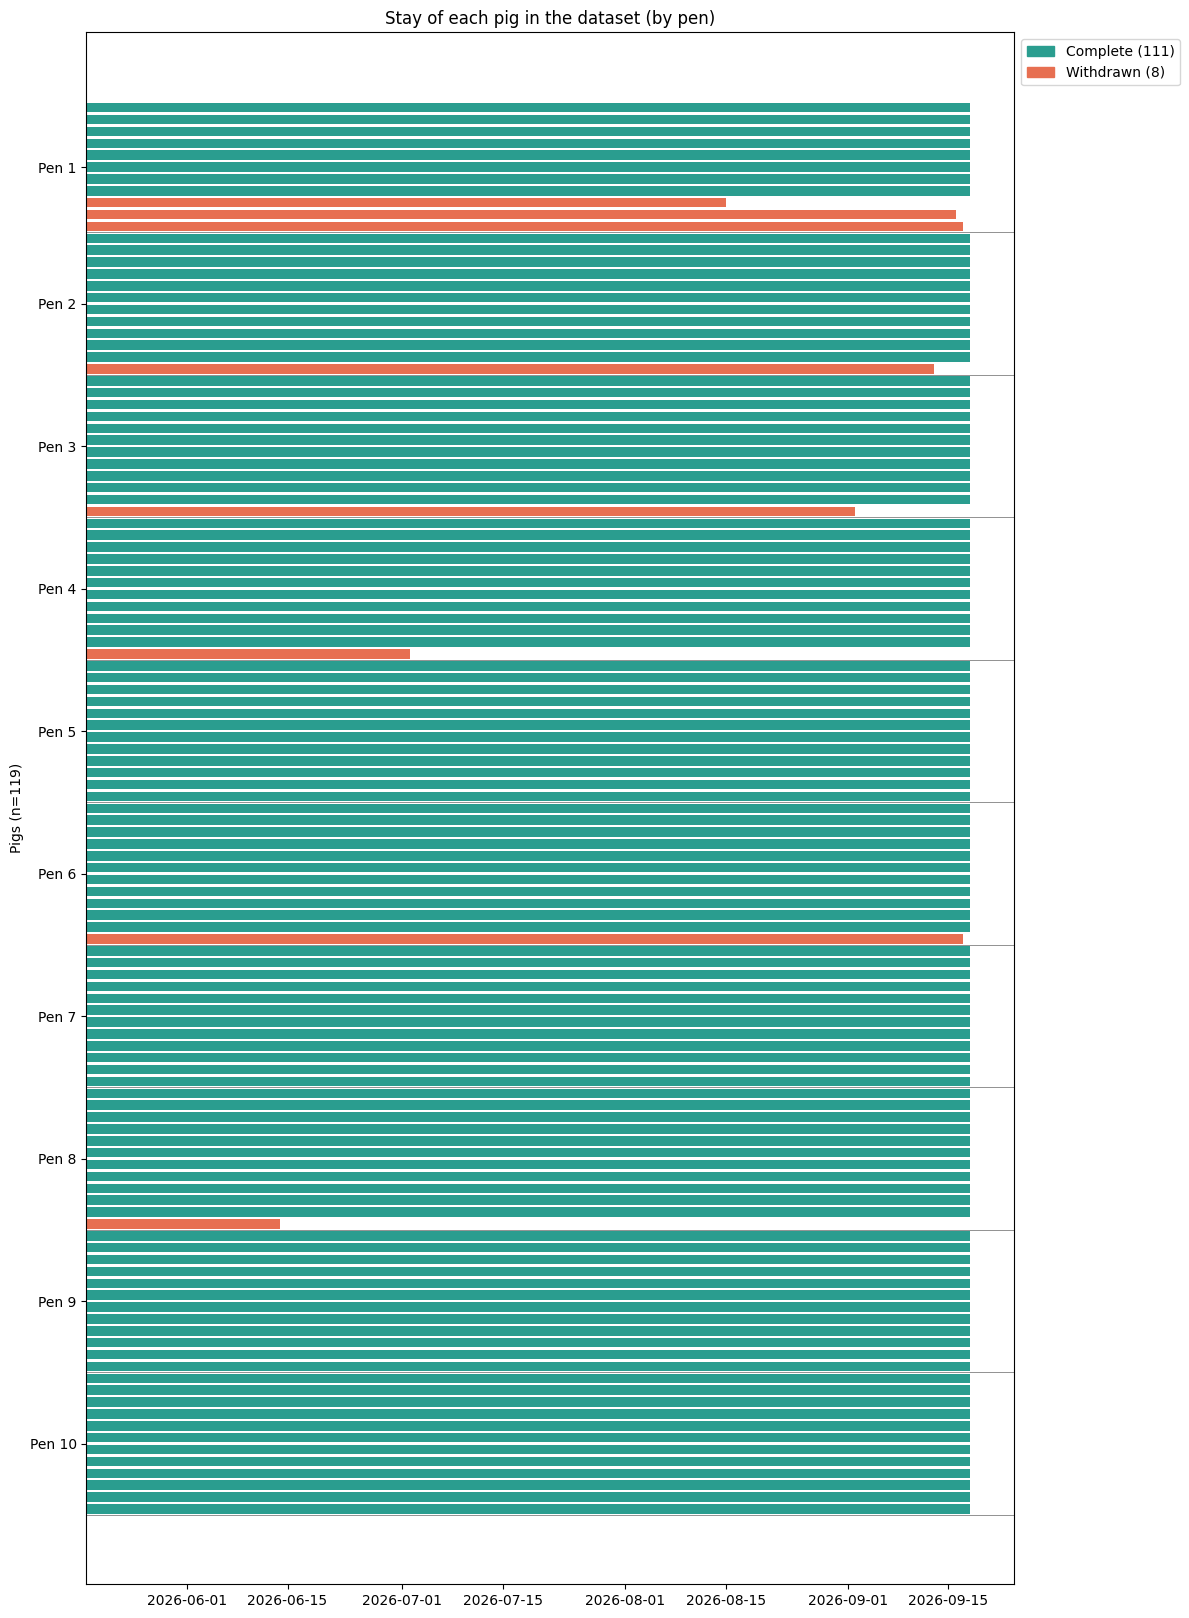

In [12]:
plot_pig_timeline(pig, by_pen=True)

## 3.  Is data consistent?

### Are there repeated rows in the dataset?

In [13]:
df.duplicated().sum()   

# If the sum = 0, there is no duplication

np.int64(0)

### Are there multiple observations of the same pig the same day?

In [14]:
df.duplicated(subset=["Animal_ID", "Date"]).sum()

# If the sum = 0, there is no duplication of pig-date pairs

np.int64(0)

### Can a pig be at different pens?

In [15]:
df.groupby("Animal_ID", observed=True)["Pen"].nunique().value_counts()

# If the result is (1, 119), all pigs were in one pen only

Pen
1    119
Name: count, dtype: int64

### All 'Incidencies' have a type and 'Not-Incidencies' don't have a type

In [16]:
is_incidence = df["Incidencias"] > 0
has_type = df["Incidencias_tipo"].notna()

In [17]:
pd.crosstab(df["Incidencias"], has_type, rownames=["Incidencias"], colnames=["Has type"])

Has type,False,True
Incidencias,,
0,14293,0
1,0,68


As we can see, 'Incidencies' are consistent in the dataset

### Fattening day coincides with Date and Week

In [18]:
expected_day = (df["Date"] - df["Date"].min()).dt.days + 1

In [19]:
expected_week = np.ceil(df["Fattening_day"] / 7).astype(int)

In [20]:
day_mismatch = df["Fattening_day"] != expected_day
week_mismatch = df["Week"] != expected_week

In [21]:
print("Fattening_day inconsistent with Date:", day_mismatch.sum())
print("Week inconsistent with Fattening_day:", week_mismatch.sum())

# If it's 0 for both, it's consistent

Fattening_day inconsistent with Date: 0
Week inconsistent with Fattening_day: 0


### Water_use_pen_L and Water_use_L have a unique value per pen and day

In [22]:
g = df.groupby(["Pen", "Date"])

In [23]:
n_pen = g["Water_use_pen_L"].nunique()
n_ind = g["Water_use_L"].nunique()

In [24]:
print("Pen-days with more than one Water_use_pen_L:", (n_pen > 1).sum())
print("Pen-days with more than one Water_use_L:    ", (n_ind > 1).sum())

# If it's 0 for both, it's consistent

Pen-days with more than one Water_use_pen_L: 0
Pen-days with more than one Water_use_L:     0


### Respiratory score has a unique value per day

In [25]:
n_per_day = df.groupby("Date")["Respiratory_score"].nunique()
print("Days with more than one Respiratory_score:", (n_per_day > 1).sum())

# If it's 0, it's consistent

Days with more than one Respiratory_score: 0


## 4. Do we have impossible values?

### Are counts (duration, pigs in pen...) positive integers?

In [26]:
count_vars = ["Fattening_day", "Week", "Number_visits",
              "Respiratory_score", "Incidencias", "Animals_in_pen"]

rows = []

In [27]:
for c in count_vars:
    s = df[c].dropna()
    rows.append({
        "variable": c,
        "type": "count",
        "n_non_integer": int((s % 1 != 0).sum()),
        "n_negative": int((s < 0).sum()),
        "n_zero": int((s == 0).sum()),
        "min": s.min(),
        "max": s.max(),
    })

### Are inherently positive variables positive?

In [28]:
positive_vars = ["Feed_intake_kg", "Duration_min", "Feeding_rate_g_min",
                 "Body_weight_kg", "FCR", "Water_use_L", "Water_use_pen_L"]

In [29]:
for c in positive_vars:
    s = df[c].dropna()
    rows.append({
        "variable": c,
        "type": "positive",
        "n_non_integer": None,
        "n_negative": int((s < 0).sum()),
        "n_zero": int((s == 0).sum()),
        "min": s.min(),
        "max": s.max(),
    })

In [30]:
impossible = pd.DataFrame(rows).set_index("variable")
impossible

,type,n_non_integer,n_negative,n_zero,min,max
variable,,,,,,
Fattening_day,count,0.0,0,0,1.000,123.000
Week,count,0.0,0,0,1.000,18.000
Number_visits,count,0.0,0,0,1.000,30.000
Respiratory_score,count,0.0,0,0,31.000,91.000
Incidencias,count,0.0,0,14293,0.000,1.000
Animals_in_pen,count,0.0,0,0,8.000,12.000
Feed_intake_kg,positive,NaN,0,0,0.001,5.695
Duration_min,positive,NaN,0,0,0.070,151.850
Feeding_rate_g_min,positive,NaN,0,0,0.280,330.000


As we can see, variables have a correct type

## 5. How are outliers distributed across dataset?

### Overview of outlier distribution

In [31]:
import matplotlib.pyplot as plt

In [32]:
cols = ["Feed_intake_kg", "Number_visits", "Duration_min", "Feeding_rate_g_min",
            "Body_weight_kg", "ADG_kg_d", "FCR", "RFI_kg_d",
            "Water_use_L", "Respiratory_score", "Water_use_pen_L"]

In [33]:
outlier_table = df[cols].apply(outlier_summary).T.round(2)
outlier_table

,min,max,outlier_threshold_inf,outlier_threshold_sup,n_outliers,%_outliers
Feed_intake_kg,0.00,5.70,0.56,3.71,221.0,1.54
Number_visits,1.00,30.00,0.00,16.00,433.0,3.02
Duration_min,0.07,151.85,10.23,92.86,240.0,1.67
Feeding_rate_g_min,0.28,330.00,-8.34,88.65,266.0,1.86
Body_weight_kg,20.67,148.86,-22.82,172.10,0.0,0.00
ADG_kg_d,-4.86,9.75,0.11,1.49,580.0,4.05
FCR,0.28,492.40,0.04,5.53,807.0,5.77
RFI_kg_d,-2.10,1.82,-0.76,0.77,490.0,3.42
Water_use_L,2.25,43.67,-3.55,25.25,452.0,3.43
Respiratory_score,31.00,91.00,18.50,110.50,0.0,0.00


We can also visualize the outliers using boxplots

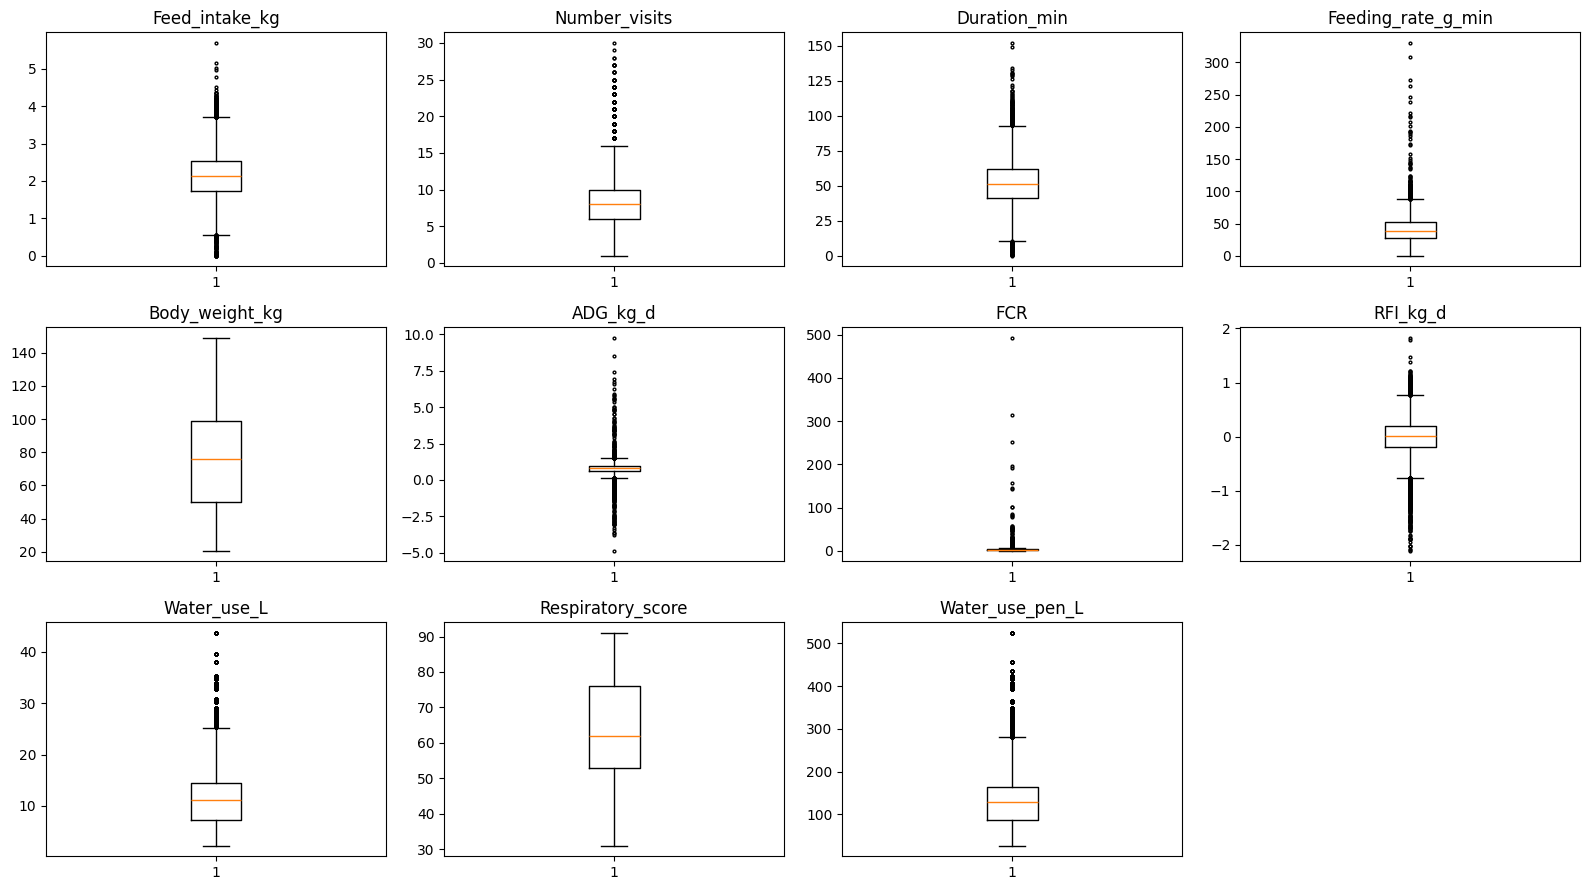

In [34]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.ravel(), cols):
    ax.boxplot(df[c].dropna(), flierprops={"markersize": 2})
    ax.set_title(c)
for ax in axes.ravel()[len(cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Outlier distribution using week as a reference

In [35]:
weekly_outlier_table = df[cols].apply(weekly_outlier_stats, data=df, group="Week").T.round(2)
weekly_outlier_table

,n,n_weekly_outliers,pct_weekly_mild
Feed_intake_kg,14338.0,336.0,2.34
Number_visits,14338.0,310.0,2.16
Duration_min,14338.0,353.0,2.46
Feeding_rate_g_min,14338.0,319.0,2.22
Body_weight_kg,14230.0,646.0,4.54
ADG_kg_d,14309.0,673.0,4.70
FCR,13987.0,1020.0,7.29
RFI_kg_d,14309.0,539.0,3.77
Water_use_L,13197.0,618.0,4.68
Respiratory_score,14361.0,462.0,3.22


### Outlier distribution by pig

In [36]:
ind_cols = ["Feed_intake_kg", "Number_visits", "Duration_min", "Feeding_rate_g_min",
            "Body_weight_kg", "ADG_kg_d", "FCR", "RFI_kg_d"]

animal_out = animal_outlier_stats(df, ind_cols)
animal_out.head(10).round(1)

,Feed_intake_kg,Number_visits,Duration_min,Feeding_rate_g_min,Body_weight_kg,ADG_kg_d,FCR,RFI_kg_d,pct_days_with_outlier,outliers_per_100_obs
Animal_ID,,,,,,,,,,
682544,0.8,52.0,4.1,0.0,0.0,2.4,5.7,0.0,59.3,8.1
482572,1.6,0.0,0.0,7.3,0.0,14.6,30.1,22.8,52.8,9.6
382602,0.0,13.8,35.8,0.8,0.0,1.6,2.4,1.6,47.2,7.0
682516,1.6,0.0,4.1,36.6,0.0,3.3,7.3,13.8,46.3,8.3
982668,3.3,4.1,12.2,0.0,0.0,7.3,17.9,22.0,46.3,8.3
482538,0.8,0.0,0.0,0.0,0.0,13.8,27.6,17.1,44.7,7.4
582521,2.5,0.0,0.0,1.6,0.0,24.6,17.2,1.6,44.3,5.9
782579,0.0,0.0,0.0,0.8,0.0,23.6,18.7,6.5,43.9,6.2
382675,0.0,23.6,0.0,0.8,0.0,13.0,12.2,11.4,41.5,7.6


This table shows the 10 pigs with the highest percentage of days with at least one outlier (`pct_days_with_outlier`). For each variable, the value is the percentage of that pig's days in which the variable was an outlier, using the global IQR fences. `n_outliers` is the total count of outlier values for that pig (one per variable and day), and `outliers_per_100_obs` is that count relative to the total number of pig-day-variable observations.

### Outlier distribution by pen

In [37]:
pen_out = group_outlier_stats(df, ind_cols, "Pen")
pen_out.round(1)

,Feed_intake_kg,Number_visits,Duration_min,Feeding_rate_g_min,Body_weight_kg,ADG_kg_d,FCR,RFI_kg_d,pct_days_with_outlier,outliers_per_100_obs
Pen,,,,,,,,,,
4,1.2,1.6,0.9,2.1,0.0,6.8,9.8,7.2,21.6,3.7
6,0.8,7.2,1.4,4.0,0.0,3.1,6.1,2.9,20.7,3.2
9,1.5,1.9,1.9,3.6,0.0,4.7,7.8,3.7,19.9,3.1
3,2.1,6.1,5.0,1.0,0.0,3.0,4.4,3.4,18.6,3.1
1,1.8,2.4,0.7,1.6,0.0,3.1,5.2,5.1,15.1,2.5
8,2.2,1.1,2.0,0.1,0.0,4.3,4.7,3.3,14.5,2.2
5,2.0,3.9,1.0,0.9,0.0,3.7,4.5,1.2,14.4,2.1
10,1.0,1.6,1.3,1.9,0.0,4.8,5.0,3.5,14.4,2.4
2,1.8,3.1,2.0,0.3,0.0,3.3,4.2,2.9,13.6,2.2


This table ranks the pens by the percentage of pig-days with at least one outlier (`pct_days_with_outlier`). For each variable, the value is the percentage of the pen's pig-day observations in which the variable was an outlier, using the global IQR fences. `outliers_per_100_obs` is the number of outlier values per 100 pig-day-variable observations, so days with several simultaneous outliers weigh more. 

### Are the differences between pens larger than the differences between pigs?

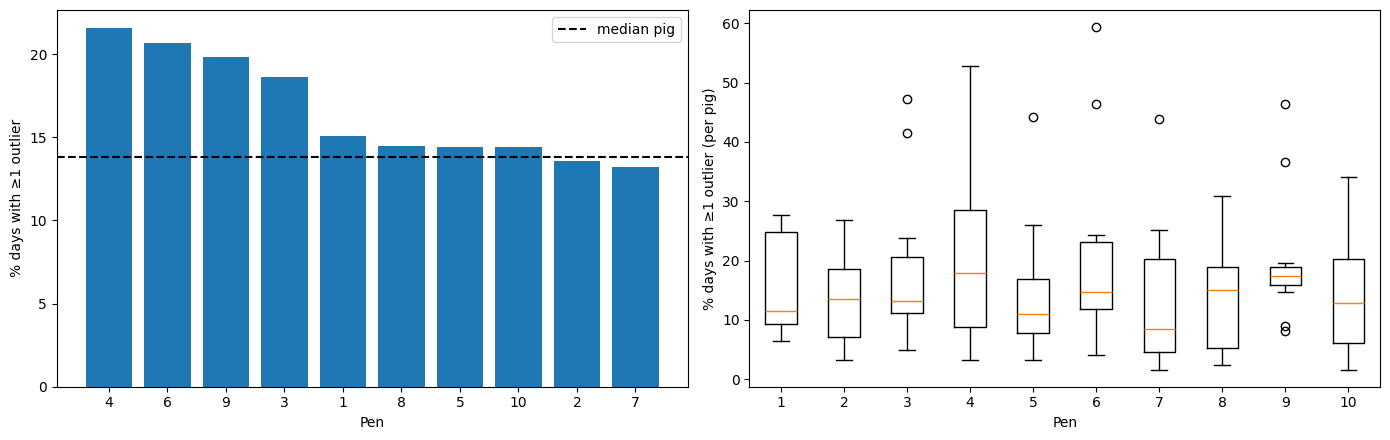

KruskalResult(statistic=np.float64(7.651072235737965), pvalue=np.float64(0.5696555294959964))


In [38]:
# Are the differences between pens larger than the differences between pigs?
from scipy.stats import kruskal

pig_rate = outlier_flags(df, ind_cols).any(axis=1).groupby(df["Animal_ID"]).mean() * 100
pig_pen = df.groupby("Animal_ID")["Pen"].first()
pens = sorted(pig_pen.unique())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].bar(pen_out.index.astype(str), pen_out["pct_days_with_outlier"])
axes[0].axhline(pig_rate.median(), color="k", ls="--", label="median pig")
axes[0].set_xlabel("Pen")
axes[0].set_ylabel("% days with ≥1 outlier")
axes[0].legend()

axes[1].boxplot([pig_rate[pig_pen == p] for p in pens])
axes[1].set_xticklabels(pens)
axes[1].set_xlabel("Pen")
axes[1].set_ylabel("% days with ≥1 outlier (per pig)")

plt.tight_layout()
plt.show()

print(kruskal(*[pig_rate[pig_pen == p] for p in pens]))

The bar plot (left) shows the percentage of pig-days with at least one outlier in each pen. Pens 4, 6, 9 and 3 are above 18%, while the rest are around 13-15%. However, the boxplot (right), which shows the same percentage per pig within each pen, reveals that the variability within a pen is larger than the differences between pens: the boxes overlap heavily and pen medians range only from about 8% to 18%. The pens at the top of the bar plot are driven by a few extreme pigs (for example, one pig above 50% in pens 4 and 6, and two pigs above 40% in pen 3), which raise the pen average. This is consistent with the Kruskal-Wallis test (p = 0.57), so for the individual-level variables outliers are explained by specific animals rather than by a pen effect.

## 6. Do we have missing data? How can we caracterize missigness?

### What is the proportion of missing values for each variable?

In [39]:
nuls = df.isna().sum()

pct = (df.isna().mean() * 100).round(2)

pd.DataFrame({"nuls": nuls, "%": pct}).query("nuls > 0")

# Number and propotion of missing values for eaach variable.

# Variables without missing values are not shown. Ignore 'Incidencias_tipo' since non-incidences have not a explicit type

,nuls,%
Feed_intake_kg,23,0.16
Number_visits,23,0.16
Duration_min,23,0.16
Feeding_rate_g_min,23,0.16
Body_weight_kg,131,0.91
ADG_kg_d,52,0.36
FCR,374,2.60
RFI_kg_d,52,0.36
Water_use_L,1164,8.11
Incidencias_tipo,14293,99.53


### What is the proportion of missing values per pen?

In [40]:
miss_cols = ["Feed_intake_kg", "Number_visits", "Duration_min", "Feeding_rate_g_min",
             "Body_weight_kg", "ADG_kg_d", "FCR", "RFI_kg_d"]


In [41]:
pen_missing = df[miss_cols].isna().groupby(df["Pen"]).mean().mul(100)

In [42]:
pen_day = df.drop_duplicates(["Pen", "Date"])
pen_missing["Water_use_pen_L"] = (pen_day["Water_use_pen_L"].isna()
                                  .groupby(pen_day["Pen"]).mean().mul(100))

In [43]:
pen_missing.round(1)

,Feed_intake_kg,Number_visits,Duration_min,Feeding_rate_g_min,Body_weight_kg,ADG_kg_d,FCR,RFI_kg_d,Water_use_pen_L
Pen,,,,,,,,,
1,0.2,0.2,0.2,0.2,1.5,0.5,2.1,0.5,0.0
2,0.3,0.3,0.3,0.3,0.3,0.3,2.3,0.3,0.0
3,0.2,0.2,0.2,0.2,0.9,0.5,2.2,0.5,0.0
4,0.4,0.4,0.4,0.4,1.2,0.6,4.4,0.6,0.0
5,0.0,0.0,0.0,0.0,0.5,0.3,1.9,0.3,0.0
6,0.0,0.0,0.0,0.0,0.6,0.0,1.5,0.0,0.0
7,0.0,0.0,0.0,0.0,1.0,0.2,2.8,0.2,78.0
8,0.3,0.3,0.3,0.3,0.7,0.4,3.1,0.4,0.0
9,0.1,0.1,0.1,0.1,1.7,0.5,3.0,0.5,0.0


Feed values share missigness

Also, it's important to note that pen 7 has a total of 78% of missigness in water use mesurement, which means that the sensor could have failed for a prolonged time.

## 7. Which variables can have leakage?

By reading information added to the dataset:

`Feed_intake_kg`, `Number_visits`, `Duration_min`, `Feeding_rate_g_min`, `Week` -> Do not have leakage

`Body_weight` -> Does not have leakage in theory, but the data has some inconsistencies that could result in leakage and we should adress this

`ADG` -> Includes 3 future days in the calculation, since it's a 7-day window. Therefore, has leakage

`FCR`, `RFI_kg_d` -> Are calculated using `ADG`, thus, have leakage

`Respiratory_score` -> Depends on how the score is generated, to our knowledge, does not have leakage

`Water_use_L`, `Water_use_pen_L` -> It is calculated using the reading of the folowwing day. Thus, has leakage

`Animals_in_pen`, `Reliable_day` -> Do not have leakage

## Discussion: Conclusions and decisions